# 14 — SmolVLA: Vision-Language-Action Policies

## 1. From ACT to Vision-Language-Action Models

In the previous notebook, we evaluated a pretrained ACT policy
on LIBERO-Goal.

ACT predicts robot actions from visual observations and
proprioceptive state:

$$
\mathbf{A}_{t:t+H} =
\pi_\theta(I_t, \mathbf{s}_t)
$$

A Vision-Language-Action (VLA) policy additionally conditions
its behavior on a natural-language instruction:

$$
\mathbf{A}_{t:t+H} =
\pi_\theta(I_t, \mathbf{s}_t, \ell)
$$

where:

- $I_t$: visual observations from one or more cameras.
- $\mathbf{s}_t$: robot proprioceptive state.
- $\ell$: natural-language task instruction.
- $\mathbf{A}_{t:t+H}$: predicted action chunk.

For example:

> "Put the bowl on the plate."

The language instruction specifies the desired task,
while visual observations describe the current scene.

## Learning objectives

1. Understand how vision, language, and robot state are combined.
2. Explore the SmolVLA architecture.
3. Load a pretrained SmolVLA checkpoint.
4. Inspect its observation and action interfaces.
5. Determine whether it can be evaluated on LIBERO.

In [1]:
from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig

model_id = "lerobot/smolvla_base"

config = SmolVLAConfig.from_pretrained(model_id)

print("Policy type:", config.type)
print("Chunk size:", config.chunk_size)
print("Actions per inference:", config.n_action_steps)

print("\nInput features:")
for name, feature in config.input_features.items():
    print(f"  {name}: {feature.shape}")

print("\nOutput features:")
for name, feature in config.output_features.items():
    print(f"  {name}: {feature.shape}")

# Note language instruction is not an input_feature, but is provided as observation["task"].


/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Policy type: smolvla
Chunk size: 50
Actions per inference: 50

Input features:
  observation.state: (6,)
  observation.images.camera1: (3, 256, 256)
  observation.images.camera2: (3, 256, 256)
  observation.images.camera3: (3, 256, 256)

Output features:
  action: (6,)


## 3. Loading SmolVLA and Processing Language

SmolVLA combines a Vision-Language Model (VLM) with
an action generation network.

The VLM processes visual observations and natural-language
instructions, while the action expert predicts robot actions.

The policy can be represented as:

$$
\mathbf{A}_{t:t+H}
=
\pi_\theta(I_t, \mathbf{s}_t, \ell)
$$

We first load the pretrained model and its preprocessing
pipeline, then examine how a task instruction is tokenized.

The goal is to understand the language interface before
attempting robot control.

In [6]:
import torch

from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.policies.factory import make_pre_post_processors

model_id = "lerobot/smolvla_base"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

policy = SmolVLAPolicy.from_pretrained(model_id).to(device)
policy.eval()

preprocessor, postprocessor = make_pre_post_processors(
    policy_cfg=policy.config,
    pretrained_path=model_id,
)

n_params = sum(p.numel() for p in policy.parameters())

print(f"Parameters: {n_params / 1e6:.1f} M")
print(f"Device: {device}")

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 863.90it/s] 


Reducing the number of VLM layers to 16 ...
Parameters: 450.0 M
Device: cuda


In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"
)

instruction = "Put the bowl on the plate."

tokens = tokenizer(
    instruction,
    return_tensors="pt",
)

print("Instruction:", instruction)
print("\nToken IDs:", tokens["input_ids"][0].tolist())

print("\nTokens:")
print(tokenizer.convert_ids_to_tokens(tokens["input_ids"][0]))

Instruction: Put the bowl on the plate.

Token IDs: [22030, 260, 12505, 335, 260, 6496, 30]

Tokens:
['Put', 'Ġthe', 'Ġbowl', 'Ġon', 'Ġthe', 'Ġplate', '.']


## 4. Multimodal Inference with SmolVLA

We now test the complete Vision-Language-Action pipeline.

Unlike standalone tokenization, this experiment passes
a task instruction, visual observations, and robot state
through the policy's preprocessing pipeline.

SmolVLA generates actions using a flow-matching action expert.

Starting from noise, the action expert iteratively predicts
a velocity field that transforms noise into an action chunk:

$$
\frac{d\mathbf{A}_\tau}{d\tau}
=
v_\theta(\mathbf{A}_\tau,\tau \mid I,\mathbf{s},\ell)
$$

The resulting action chunk contains multiple future actions.

We use synthetic observations only to verify the model
interface and tensor dimensions, not to assess task performance.

In [8]:
import torch

policy.reset()

observation = {
    "observation.state": torch.zeros(1, 6),
    "observation.images.camera1": torch.zeros(1, 3, 256, 256),
    "observation.images.camera2": torch.zeros(1, 3, 256, 256),
    "observation.images.camera3": torch.zeros(1, 3, 256, 256),
    "task": ["Put the bowl on the plate."],
}

processed = preprocessor(observation)

print("Processed observation:")

for key, value in processed.items():
    if isinstance(value, torch.Tensor):
        print(f"{key}: {tuple(value.shape)}")
    else:
        print(f"{key}: {type(value).__name__}")

Processed observation:
action: NoneType
next.reward: float
next.done: bool
next.truncated: bool
info: dict
task: list
observation.state: (1, 6)
observation.images.camera1: (1, 3, 256, 256)
observation.images.camera2: (1, 3, 256, 256)
observation.images.camera3: (1, 3, 256, 256)
observation.language.tokens: (1, 48)
observation.language.attention_mask: (1, 48)


In [9]:
with torch.inference_mode():
    action = policy.select_action(processed)
    action = postprocessor(action)

print("Action shape:", action.shape)
print("Predicted action:", action)

[transformers] Calling `crop` with a positive value is deprecated and will be removed in version 5.18. Please use a negative integer to remove that number of tokens from the cache instead.


Action shape: torch.Size([1, 6])
Predicted action: tensor([[-0.0366,  0.2113,  0.1162,  0.1321,  0.0668, -0.2167]])


## 5. Inspecting SmolVLA Action Chunks

SmolVLA generates a sequence of future robot actions using
a flow-matching action expert.

For our checkpoint:

- Action chunk length: 50
- Action dimensionality: 6
- Conditioning: images, robot state, and language instruction

We visualize the complete predicted trajectory to examine
how the action expert produces temporally structured commands.

Since we use synthetic observations, these predictions are
not expected to correspond to meaningful robot behavior.

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import torch

device = torch.device("cuda")

policy = policy.to(device)
policy.eval()

processed_cuda = {
    key: value.to(device) if isinstance(value, torch.Tensor) else value
    for key, value in processed.items()
}

with torch.inference_mode():
    action_chunk = policy.predict_action_chunk(processed_cuda)

print("Action chunk shape:", action_chunk.shape)

Action chunk shape: torch.Size([1, 50, 6])


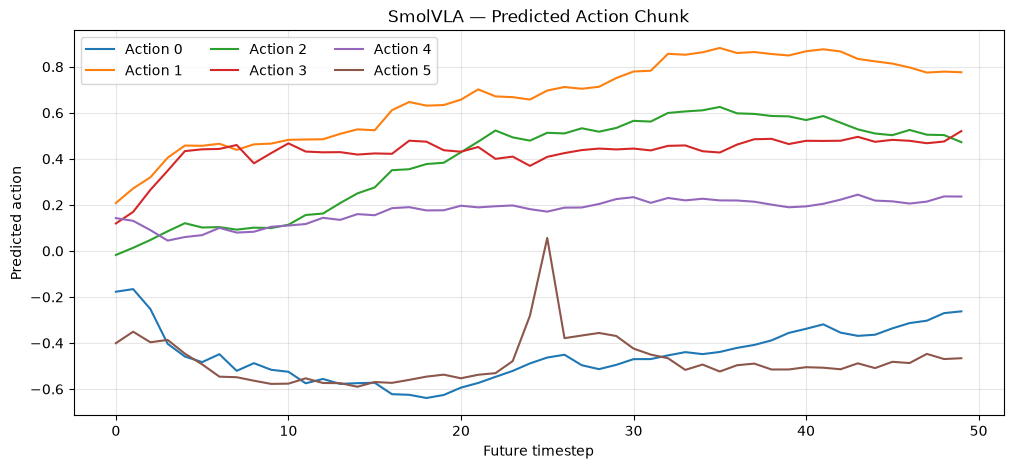

In [11]:
with torch.inference_mode():
    action_chunk = postprocessor(action_chunk)

actions = action_chunk.squeeze(0).cpu().numpy()

plt.figure(figsize=(12, 5))

for i in range(actions.shape[-1]):
    plt.plot(actions[:, i], label=f"Action {i}")

plt.xlabel("Future timestep")
plt.ylabel("Predicted action")
plt.title("SmolVLA — Predicted Action Chunk")
plt.legend(ncol=3)
plt.grid(alpha=0.3)
plt.show()

## 6. Language Conditioning Experiment

We investigate whether changing the language instruction
affects the actions predicted by SmolVLA.

We keep the visual observations and robot state fixed,
and change only the task instruction.

Since SmolVLA uses flow matching, we control the random
seed to reduce differences caused by stochastic sampling.

We compare the predicted action chunks using the mean
absolute difference:

$$
D = \frac{1}{HD}
\sum_{t=1}^{H}
\sum_{j=1}^{D}
\left|A_{t,j}^{(1)} - A_{t,j}^{(2)}\right|
$$

This experiment measures sensitivity to language, not
whether the resulting actions accomplish either task.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import torch

instructions = [
    "Pick up the object.",
    "Move the object to the left.",
]

predictions = []

for instruction in instructions:

    obs = {
        **observation,
        "task": [instruction],
    }

    processed_obs = preprocessor(obs)

    processed_obs = {
        k: v.to(device) if isinstance(v, torch.Tensor) else v
        for k, v in processed_obs.items()
    }

    # Same random seed -> same initial noise.
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    policy.reset()

    with torch.inference_mode():
        chunk = policy.predict_action_chunk(processed_obs)
        chunk = postprocessor(chunk)

    predictions.append(chunk.squeeze(0).cpu().numpy())

actions_pick, actions_left = predictions

print("Shape:", actions_pick.shape)

difference = np.mean(np.abs(actions_pick - actions_left))

print(f"Mean absolute difference: {difference:.6f}")

Shape: (50, 6)
Mean absolute difference: 0.124449


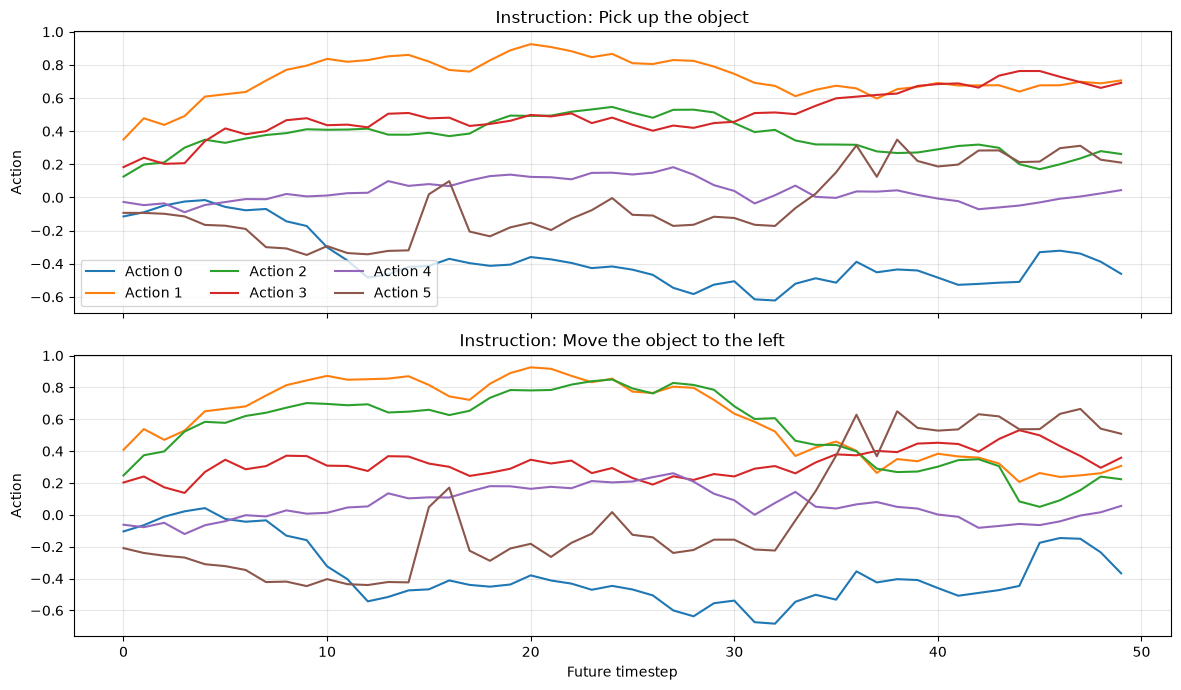

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for i in range(6):
    axes[0].plot(
        actions_pick[:, i],
        label=f"Action {i}",
    )

axes[0].set_title("Instruction: Pick up the object")
axes[0].set_ylabel("Action")
axes[0].legend(ncol=3)
axes[0].grid(alpha=0.3)

for i in range(6):
    axes[1].plot(
        actions_left[:, i],
        label=f"Action {i}",
    )

axes[1].set_title("Instruction: Move the object to the left")
axes[1].set_xlabel("Future timestep")
axes[1].set_ylabel("Action")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Evaluate SmolVLA on LIBERO

```bash
export MUJOCO_GL=egl

pixi run -e cuda lerobot-eval \
  --policy.path=lerobot/smolvla_libero \
  --env.type=libero \
  --env.task=libero_goal \
  --env.task_ids='[8]' \
  --env.control_mode=relative \
  --env.init_states=true \
  --env.hard_reset=true \
  --env.observation_height=256 \
  --env.observation_width=256 \
  --eval.batch_size=1 \
  --eval.n_episodes=5 \
  --env.max_parallel_tasks=1 \
  --rename_map='{"observation.images.image":"observation.images.camera1","observation.images.image2":"observation.images.camera2"}' \
  --output_dir=./outputs/eval_smolvla_libero_goal
  ```

## Multi-task Evaluation of SmolVLA on LIBERO

Model card for lerobot/smolvla_libero shows that is trained on lerobot/libero dataset, which contains 40 tasks

```bash
export MUJOCO_GL=egl

pixi run -e cuda lerobot-eval \
  --policy.path=lerobot/smolvla_libero \
  --env.type=libero \
  --env.task=libero_goal \
  --env.task_ids='[0,1,2,3,4,5,6,7,8,9]' \
  --env.control_mode=relative \
  --env.init_states=true \
  --env.hard_reset=true \
  --env.observation_height=256 \
  --env.observation_width=256 \
  --eval.batch_size=1 \
  --eval.n_episodes=5 \
  --env.max_parallel_tasks=1 \
  --rename_map='{"observation.images.image":"observation.images.camera1","observation.images.image2":"observation.images.camera2"}' \
  --output_dir=./outputs/eval_smolvla_libero_goal_all
  ```

## Offline Imitation Evaluation: SmolVLA vs Expert

In closed-loop evaluation, the policy's actions influence future observations.
This makes it difficult to distinguish imitation errors from accumulated
control errors.

We now evaluate SmolVLA in an open-loop setting using expert demonstrations
from the LeRobot LIBERO dataset.

For each expert observation, we compare the action predicted by SmolVLA
with the recorded expert action, without executing the prediction.

Our goals are to:
1. Compare predicted and expert actions.
2. Measure imitation error over time.
3. Identify phases where the policy deviates from the expert.
4. Relate offline imitation quality to closed-loop task success.

In [1]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset(
    repo_id="lerobot/libero",
)

print("Episodes:", dataset.num_episodes)
print("Frames:", dataset.num_frames)

print("\nFeatures:")
for name, feature in dataset.features.items():
    print(f"  {name}: {feature}")

print("\nTask 8:")
for task_id, description in dataset.meta.tasks.items():
    if task_id == 8:
        print(task_id, description)

/home/terreran/playground_ws/robot-learning-playground/.pixi/envs/cuda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 457 files: 100%|██████████| 457/457 [00:57<00:00,  7.94it/s]


Episodes: 1693
Frames: 273465

Features:
  observation.images.image: {'dtype': 'video', 'shape': (256, 256, 3), 'names': ['height', 'width', 'channel'], 'fps': 10.0, 'info': {'video.height': 256, 'video.width': 256, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'video.fps': 10, 'video.channels': 3, 'has_audio': False}}
  observation.images.image2: {'dtype': 'video', 'shape': (256, 256, 3), 'names': ['height', 'width', 'channel'], 'fps': 10.0, 'info': {'video.height': 256, 'video.width': 256, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'video.fps': 10, 'video.channels': 3, 'has_audio': False}}
  observation.state: {'dtype': 'float32', 'shape': (8,), 'names': ['state'], 'fps': 10.0}
  action: {'dtype': 'float32', 'shape': (7,), 'names': ['actions'], 'fps': 10.0}
  timestamp: {'dtype': 'float32', 'shape': (1,), 'names': None}
  frame_index: {'dtype': 'int64', 'shape': (1,), 'names': None}
  episode_index: {'dtype': 'int64

In [2]:
# Find the dataset task corresponding to LIBERO-Goal task 8.
# We previously evaluated: "Put the bowl on the plate".

matches = [
    (task_id, description)
    for task_id, description in dataset.meta.tasks.items()
    if "bowl" in str(description).lower()
    and "plate" in str(description).lower()
]

print("Matching tasks:")
for task_id, description in matches:
    print(f"  {task_id}: {description}")

Matching tasks:
  task_index: task
put the white mug on the left plate and put the yellow and white mug on the right plate      0
put the white mug on the plate and put the chocolate pudding to the right of the plate       1
put the yellow and white mug in the microwave and close it                                   2
turn on the stove and put the moka pot on it                                                 3
put both the alphabet soup and the cream cheese box in the basket                            4
put both the alphabet soup and the tomato sauce in the basket                                5
put both moka pots on the stove                                                              6
put both the cream cheese box and the butter in the basket                                   7
put the black bowl in the bottom drawer of the cabinet and close it                          8
pick up the book and place it in the back compartment of the caddy                           9
put the bowl on

### Expert demonstration: LIBERO-Goal Task 8

We select an expert demonstration for the instruction
"put the bowl on the plate" (`task_index=10` in the LeRobot dataset).

The goal is to compare the expert's recorded actions with SmolVLA
predictions conditioned on the same observations.

Unlike closed-loop evaluation, the policy will not control the environment:
all observations will come from the expert trajectory.

Matching episodes: 49
Selected episode: 379
Number of frames: 112
Task: put the bowl on the plate
State shape: torch.Size([8])
Action shape: torch.Size([7])


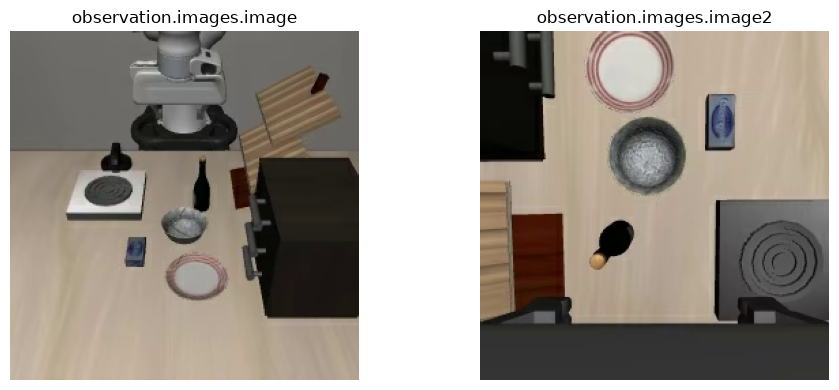

In [4]:
import matplotlib.pyplot as plt
import numpy as np

TASK_INDEX = 10  # "put the bowl on the plate"

# Search in metadata only (no image decoding).
task_indices = np.asarray(dataset.hf_dataset["task_index"])
episode_indices = np.asarray(dataset.hf_dataset["episode_index"])

# Find all episodes belonging to the selected task.
matching_episode_ids = np.unique(
    episode_indices[task_indices == TASK_INDEX]
)

print("Matching episodes:", len(matching_episode_ids))

episode_id = int(matching_episode_ids[0])

# Indices of all frames in this episode.
frame_indices = np.flatnonzero(episode_indices == episode_id)

print("Selected episode:", episode_id)
print("Number of frames:", len(frame_indices))

# Load the first observation.
sample = dataset[int(frame_indices[0])]

print("Task:", sample["task"])
print("State shape:", sample["observation.state"].shape)
print("Action shape:", sample["action"].shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, key in zip(
    axes,
    ["observation.images.image", "observation.images.image2"]
):
    image = sample[key].permute(1, 2, 0).numpy()
    ax.imshow(image)
    ax.set_title(key)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Teacher-forced action prediction

We evaluate SmolVLA using observations recorded during an expert
demonstration.

At each timestep, the policy receives the expert's observation
(images, robot state, and language instruction) and predicts an
action chunk.

We first compare the first predicted action with the expert action
at the same timestep.

Because SmolVLA uses flow matching, action generation is stochastic.
We fix the random seed to make the experiment reproducible.

In [5]:
import torch
import numpy as np

from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.policies.factory import make_pre_post_processors

MODEL_ID = "lerobot/smolvla_libero"
device = torch.device("cuda")

# Load policy and its preprocessing pipeline.
policy = SmolVLAPolicy.from_pretrained(MODEL_ID).to(device)
policy.eval()

preprocessor, postprocessor = make_pre_post_processors(
    policy_cfg=policy.config,
    pretrained_path=MODEL_ID,
)

# Expert observation at the first timestep.
sample = dataset[int(frame_indices[0])]

observation = {
    "observation.state": sample["observation.state"].unsqueeze(0),
    "observation.images.camera1": sample["observation.images.image"].unsqueeze(0),
    "observation.images.camera2": sample["observation.images.image2"].unsqueeze(0),
    "task": [sample["task"]],
}

# Preprocess and move tensors to GPU.
processed = preprocessor(observation)

processed = {
    k: v.to(device) if isinstance(v, torch.Tensor) else v
    for k, v in processed.items()
}

# Predict a full action chunk.
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

policy.reset()

with torch.inference_mode():
    predicted_chunk = policy.predict_action_chunk(processed)
    predicted_chunk = postprocessor(predicted_chunk)

# Compare first predicted action with expert action.
predicted_action = predicted_chunk[0, 0].cpu().numpy()
expert_action = sample["action"].cpu().numpy()

print("Expert action:   ", np.round(expert_action, 4))
print("Predicted action:", np.round(predicted_action, 4))

print(
    "MAE:",
    np.mean(np.abs(predicted_action - expert_action))
)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1060.57it/s]


Reducing the number of VLM layers to 16 ...


[transformers] Calling `crop` with a positive value is deprecated and will be removed in version 5.18. Please use a negative integer to remove that number of tokens from the cache instead.


Expert action:    [ 0.0723  0.     -0.     -0.0118  0.0439  0.0354 -1.    ]
Predicted action: [ 1.0070e-01  1.2280e-01  1.0400e-02  8.0000e-04  1.0200e-02  2.0900e-02
 -1.0008e+00]
MAE: 0.031887945


### Open-loop action prediction over an expert trajectory

We evaluate SmolVLA on every observation of a recorded expert
demonstration.

At each timestep:
1. Read the expert observation.
2. Predict an action chunk with SmolVLA.
3. Compare the first predicted action against the expert action.
4. Advance to the next recorded expert observation.

The environment is never stepped using the policy's predictions.

This isolates action imitation from closed-loop error accumulation.

In [7]:
from tqdm.auto import tqdm
import numpy as np
import torch
import matplotlib.pyplot as plt

expert_actions = []
predicted_actions = []

policy.reset()

for idx in tqdm(frame_indices, desc="SmolVLA offline evaluation"):

    sample = dataset[int(idx)]

    observation = {
        "observation.state": sample["observation.state"].unsqueeze(0),
        "observation.images.camera1": sample["observation.images.image"].unsqueeze(0),
        "observation.images.camera2": sample["observation.images.image2"].unsqueeze(0),
        "task": [sample["task"]],
    }

    processed = preprocessor(observation)

    processed = {
        k: v.to(device) if isinstance(v, torch.Tensor) else v
        for k, v in processed.items()
    }

    # Reproducible stochastic sampling.
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    with torch.inference_mode():
        chunk = policy.predict_action_chunk(processed)
        chunk = postprocessor(chunk)

    predicted_actions.append(
        chunk[0, 0].cpu().numpy()
    )

    expert_actions.append(
        sample["action"].cpu().numpy()
    )

expert_actions = np.stack(expert_actions)
predicted_actions = np.stack(predicted_actions)

errors = np.abs(predicted_actions - expert_actions)

print("Expert actions:", expert_actions.shape)
print("Predicted actions:", predicted_actions.shape)
print("Overall MAE:", errors.mean())

print("\nMAE per action dimension:")
for i, mae in enumerate(errors.mean(axis=0)):
    print(f"  Action {i}: {mae:.4f}")

SmolVLA offline evaluation: 100%|██████████| 112/112 [00:22<00:00,  5.06it/s]

Expert actions: (112, 7)
Predicted actions: (112, 7)
Overall MAE: 0.020732602

MAE per action dimension:
  Action 0: 0.0328
  Action 1: 0.0477
  Action 2: 0.0312
  Action 3: 0.0048
  Action 4: 0.0116
  Action 5: 0.0066
  Action 6: 0.0104


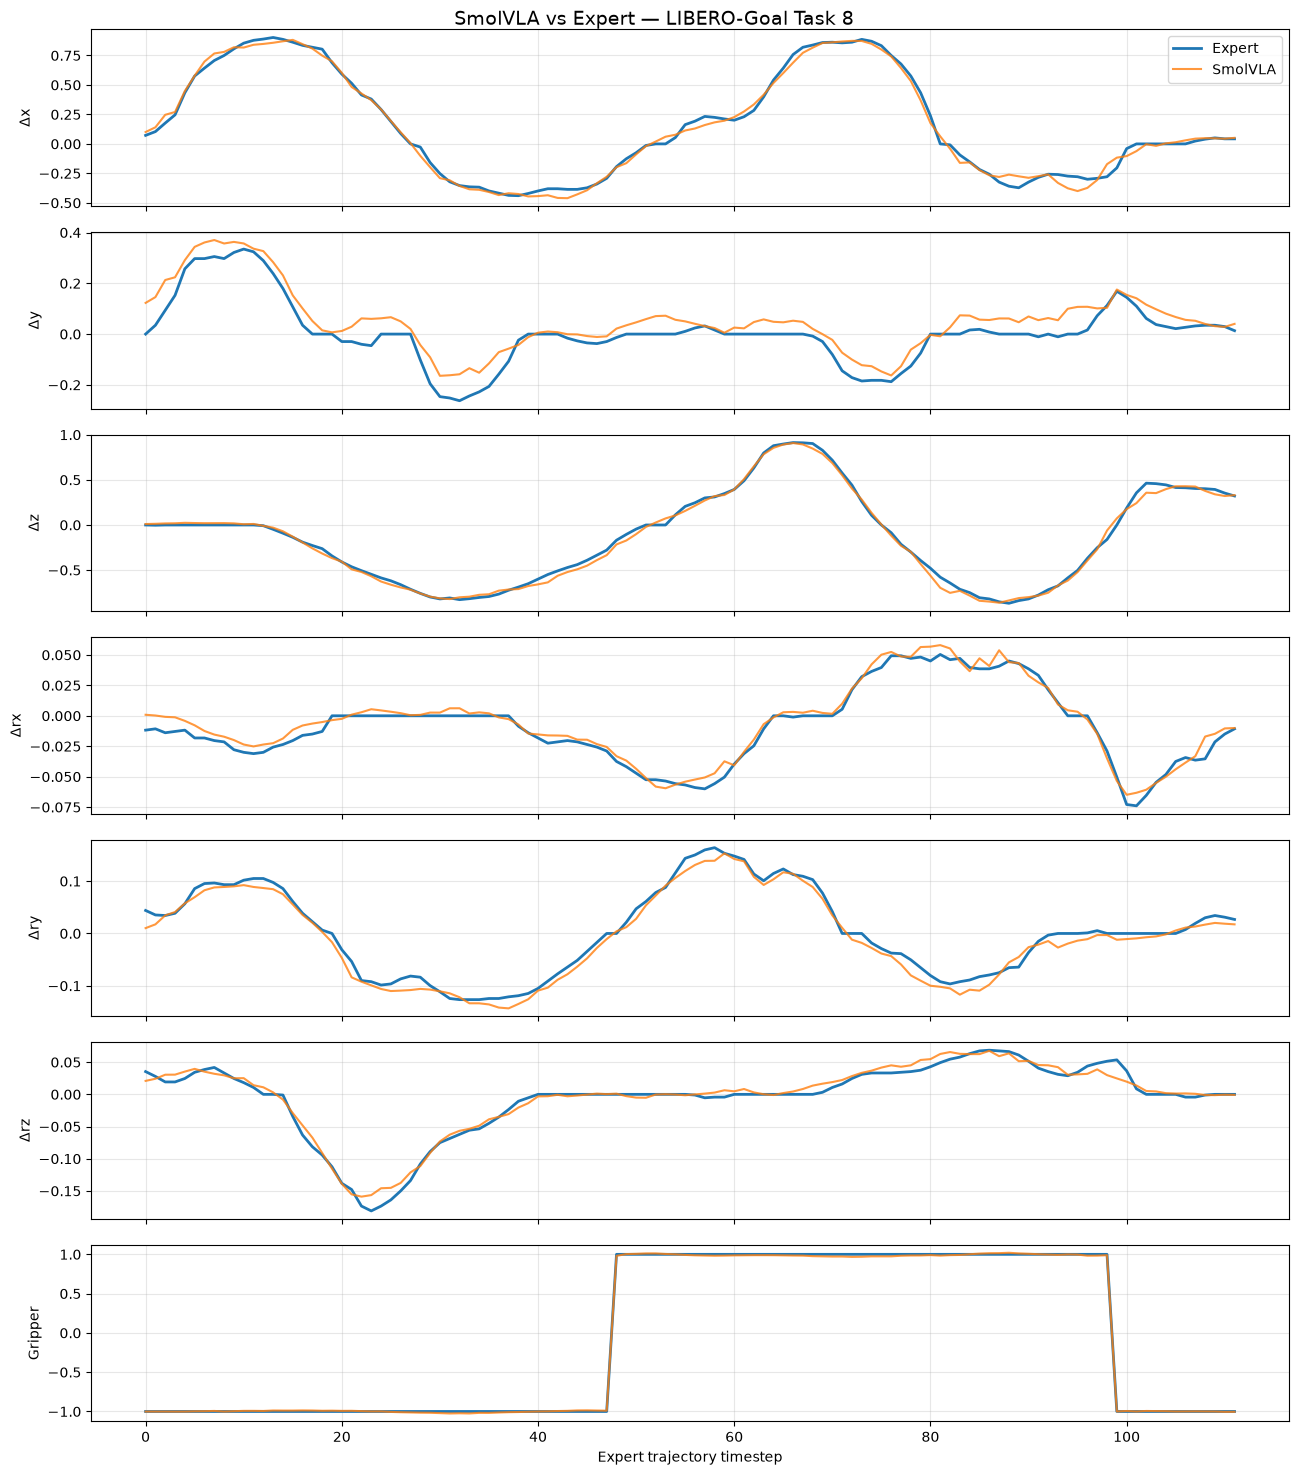

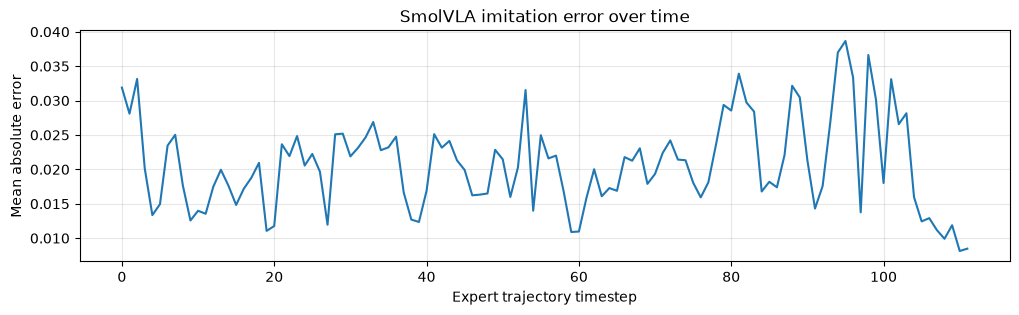

In [9]:
action_names = [
    "Δx", "Δy", "Δz",
    "Δrx", "Δry", "Δrz",
    "Gripper",
]

fig, axes = plt.subplots(
    7, 1,
    figsize=(13, 15),
    sharex=True
)

for d, ax in enumerate(axes):

    ax.plot(
        expert_actions[:, d],
        label="Expert",
        linewidth=2,
    )

    ax.plot(
        predicted_actions[:, d],
        label="SmolVLA",
        alpha=0.8,
    )

    ax.set_ylabel(action_names[d])
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Expert trajectory timestep")

plt.suptitle(
    "SmolVLA vs Expert — LIBERO-Goal Task 8",
    fontsize=14,
)

plt.tight_layout()
plt.show()

# Per-timestep imitation error
plt.figure(figsize=(12, 3))

plt.plot(errors.mean(axis=1))
plt.xlabel("Expert trajectory timestep")
plt.ylabel("Mean absolute error")
plt.title("SmolVLA imitation error over time")
plt.grid(alpha=0.3)
plt.show()

In [10]:
# Quick language-conditioning test
instructions = {
    "Correct": "put the bowl on the plate",
    "Wrong": "put the bowl on the stove",
}

test_indices = frame_indices[::max(1, len(frame_indices) // 20)][:20]

results = {}

for label, instruction in instructions.items():
    predictions = []
    targets = []

    for idx in test_indices:
        sample = dataset[int(idx)]

        obs = {
            "observation.state": sample["observation.state"].unsqueeze(0),
            "observation.images.camera1": sample["observation.images.image"].unsqueeze(0),
            "observation.images.camera2": sample["observation.images.image2"].unsqueeze(0),
            "task": [instruction],
        }

        processed = preprocessor(obs)
        processed = {
            k: v.to(device) if isinstance(v, torch.Tensor) else v
            for k, v in processed.items()
        }

        torch.manual_seed(42)
        torch.cuda.manual_seed_all(42)

        with torch.inference_mode():
            chunk = postprocessor(policy.predict_action_chunk(processed))

        predictions.append(chunk[0, 0].cpu().numpy())
        targets.append(sample["action"].cpu().numpy())

    predictions = np.stack(predictions)
    targets = np.stack(targets)

    results[label] = predictions

    print(f"{label:8s} | MAE: {np.abs(predictions - targets).mean():.4f}")

print(
    "Mean action difference:",
    np.abs(results["Correct"] - results["Wrong"]).mean()
)

Correct  | MAE: 0.0205
Wrong    | MAE: 0.1086
Mean action difference: 0.098358534
